In [55]:
# Important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam, SGD

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score


In [21]:
print('Start of the MLP demo: 9 inputs, 5 outputs')
print('Display of the ten basic training samples: matrix of 10 x 9')
data_X=np.array([[1,1,1,0,0,0,0,0,0], 
                [0,0,0,1,1,1,0,0,0],
                [0,0,0,0,0,0,1,1,1],
                [1,0,0,1,0,0,1,0,0],
                [0,1,0,0,1,0,0,1,0],
                [0,0,1,0,0,1,0,0,1],
                [0,0,1,0,1,0,0,0,1],
                [1,0,0,0,1,0,1,0,0],
                [0,0,1,0,1,0,1,0,0],
                [1,0,0,0,1,0,0,0,1]])
print(data_X)
print('-----------------------------------')
print('Display of output in 5-class label: matrix of 10 x 5')
data_Y=np.array([0,0,0,1,1,1,2,2,3,4])
encode_array = OneHotEncoder()  # One hot encoding
data_Y = encode_array.fit_transform(data_Y[:, None]).toarray()
print(data_Y)

Start of the MLP demo: 9 inputs, 5 outputs
Display of the ten basic training samples: matrix of 10 x 9
[[1 1 1 0 0 0 0 0 0]
 [0 0 0 1 1 1 0 0 0]
 [0 0 0 0 0 0 1 1 1]
 [1 0 0 1 0 0 1 0 0]
 [0 1 0 0 1 0 0 1 0]
 [0 0 1 0 0 1 0 0 1]
 [0 0 1 0 1 0 0 0 1]
 [1 0 0 0 1 0 1 0 0]
 [0 0 1 0 1 0 1 0 0]
 [1 0 0 0 1 0 0 0 1]]
-----------------------------------
Display of output in 5-class label: matrix of 10 x 5
[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


c:\users\gpang\appdata\local\programs\python\python36\lib\site-packages\sklearn\preprocessing\_encoders.py:371: FutureWarning: The handling of integer data will change in version 0.22. Currently, the categories are determined based on the range [0, max(values)], while in the future they will be determined based on the unique values.
If you want the future behaviour and silence this warning, you can specify "categories='auto'".
In case you used a LabelEncoder before this OneHotEncoder to convert the categories to integers, then you can now use the OneHotEncoder directly.
  warnings.warn(msg, FutureWarning)


In [22]:
# To create 50 more training cases, 50 more validation cases, 100 test cases

X=data_X
Y=data_Y
for i in range(5):
    tmp1=data_X + np.random.uniform(low=-0.1,high=0.1,size=(10,9)) # note the range of noise
    X=np.append(X,tmp1,axis=0)
    Y=np.append(Y,data_Y,axis=0)
print('Total of 60 training samples of X: dimension ',X.shape)
print('Total of 60 labelled outputs of X: dimension ',Y.shape)

Total of 60 training samples of X: dimension  (60, 9)
Total of 60 labelled outputs of X: dimension  (60, 5)


In [23]:
X_val=data_X + np.random.uniform(low=-0.1,high=0.1,size=(10,9))
Y_val=data_Y
for i in range(4):
    tmp1=data_X + np.random.uniform(low=-0.1,high=0.1,size=(10,9))
    X_val=np.append(X_val,tmp1,axis=0)
    Y_val=np.append(Y_val,data_Y,axis=0)
print('Total of 50 validation cases of X_val: dimension ',X_val.shape)
print('Total of 50 labelled outputs of X_val: dimension ',Y_val.shape)


Total of 50 validation cases of X_val: dimension  (50, 9)
Total of 50 labelled outputs of X_val: dimension  (50, 5)


In [24]:
X_test=data_X + np.random.uniform(low=-0.1,high=0.1,size=(10,9))
Y_test=data_Y
for i in range(9):
    tmp1=data_X + np.random.uniform(low=-0.1,high=0.1,size=(10,9))
    X_test=np.append(X_test,tmp1,axis=0)
    Y_test=np.append(Y_test,data_Y,axis=0)
print('Total of 100 test cases of X_test: dimension ',X_test.shape)
print('Total of 100 labelled outputs of X_test: dimension ',Y_test.shape)

Total of 100 test cases of X_test: dimension  (100, 9)
Total of 100 labelled outputs of X_test: dimension  (100, 5)


In [25]:
# define the model structure
# Dense : a regular fully connected layer

# The following is a simple one-hidden layer MLP;
# 9 inputs, 12 hidden neurons; 5 outputs with softmax
# Define the number of hidden nodes
num_hidden_nodes = 12
num_features = 9 # number of inputs)
num_classes = 5  # number of outputs)

def model_1():
    # create model
    model = Sequential()
    model.add(Dense(num_hidden_nodes, input_dim=num_features, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    # Compile model
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    # Choice of optimizer: adam (adaptive moment estimation), AdaGrad (adaptive learning rate),
    # sgd (Stochastic gradient descent), RMSprop (similar to AdaGrad), Adadelta (adaptive delta) ...
    return model

# build the model
model = model_1()
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_2 (Dense)              (None, 12)                120       
_________________________________________________________________
dense_3 (Dense)              (None, 5)                 65        
Total params: 185
Trainable params: 185
Non-trainable params: 0
_________________________________________________________________


In [26]:
# Training of the ANN
ann = model.fit(X, Y, batch_size=5, epochs=100,verbose=2, validation_data=(X_val, Y_val))

# Testing of the trained ANN with X_test
score = model.evaluate(X_test, Y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Epoch 1/100
12/12 - 0s - loss: 1.7688 - accuracy: 0.2000 - val_loss: 1.7471 - val_accuracy: 0.2000
Epoch 2/100
12/12 - 0s - loss: 1.7235 - accuracy: 0.2000 - val_loss: 1.7044 - val_accuracy: 0.2000
Epoch 3/100
12/12 - 0s - loss: 1.6817 - accuracy: 0.2000 - val_loss: 1.6657 - val_accuracy: 0.2000
Epoch 4/100
12/12 - 0s - loss: 1.6452 - accuracy: 0.2000 - val_loss: 1.6286 - val_accuracy: 0.2000
Epoch 5/100
12/12 - 0s - loss: 1.6079 - accuracy: 0.2000 - val_loss: 1.5959 - val_accuracy: 0.2000
Epoch 6/100
12/12 - 0s - loss: 1.5762 - accuracy: 0.2000 - val_loss: 1.5652 - val_accuracy: 0.2000
Epoch 7/100
12/12 - 0s - loss: 1.5461 - accuracy: 0.2000 - val_loss: 1.5358 - val_accuracy: 0.2000
Epoch 8/100
12/12 - 0s - loss: 1.5170 - accuracy: 0.2500 - val_loss: 1.5074 - val_accuracy: 0.2400
Epoch 9/100
12/12 - 0s - loss: 1.4882 - accuracy: 0.2833 - val_loss: 1.4811 - val_accuracy: 0.3400
Epoch 10/100
12/12 - 0s - loss: 1.4627 - accuracy: 0.3500 - val_loss: 1.4549 - val_accuracy: 0.3800
Epoch 11/

12/12 - 0s - loss: 0.3876 - accuracy: 1.0000 - val_loss: 0.3913 - val_accuracy: 0.9800
Epoch 84/100
12/12 - 0s - loss: 0.3810 - accuracy: 1.0000 - val_loss: 0.3846 - val_accuracy: 0.9800
Epoch 85/100
12/12 - 0s - loss: 0.3742 - accuracy: 1.0000 - val_loss: 0.3784 - val_accuracy: 0.9800
Epoch 86/100
12/12 - 0s - loss: 0.3682 - accuracy: 1.0000 - val_loss: 0.3725 - val_accuracy: 0.9800
Epoch 87/100
12/12 - 0s - loss: 0.3618 - accuracy: 1.0000 - val_loss: 0.3667 - val_accuracy: 0.9800
Epoch 88/100
12/12 - 0s - loss: 0.3561 - accuracy: 1.0000 - val_loss: 0.3608 - val_accuracy: 0.9800
Epoch 89/100
12/12 - 0s - loss: 0.3502 - accuracy: 1.0000 - val_loss: 0.3552 - val_accuracy: 0.9800
Epoch 90/100
12/12 - 0s - loss: 0.3452 - accuracy: 1.0000 - val_loss: 0.3494 - val_accuracy: 1.0000
Epoch 91/100
12/12 - 0s - loss: 0.3387 - accuracy: 1.0000 - val_loss: 0.3440 - val_accuracy: 1.0000
Epoch 92/100
12/12 - 0s - loss: 0.3332 - accuracy: 1.0000 - val_loss: 0.3383 - val_accuracy: 1.0000
Epoch 93/100


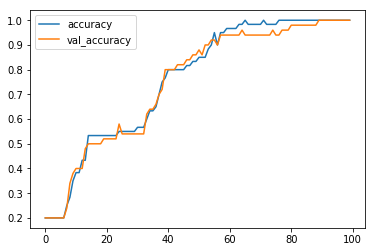

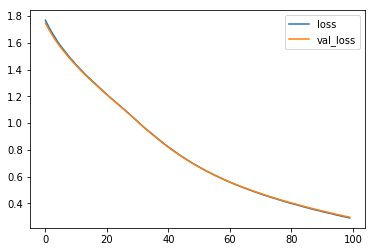

In [27]:
# To show the performance of the ANN during training
# The information has already been saved in "history"

metrics = ann.history
plt.plot(ann.epoch, metrics['accuracy'], metrics['val_accuracy'])
plt.legend(['accuracy', 'val_accuracy'])
plt.show()

plt.plot(ann.epoch, metrics['loss'], metrics['val_loss'])
plt.legend(['loss', 'val_loss'])
plt.show()

In [112]:
print('X_test.shape = ',X_test.shape)
print('Y_test.shape = ',Y_test.shape)
print('X_test[0] = ',X_test[0])
print('Y_test[0] = ',Y_test[0])

# model.predict gives the MLP output with an input X_test[0]
y_ANN_output = model.predict(X_test[0,None])
print('y_ANN_output = ',y_ANN_output)
print('softmax applied alredy')


X_test.shape =  (100, 9)
Y_test.shape =  (100, 5)
X_test[0] =  [ 0.97536321  0.95562853  0.96563981 -0.00834672 -0.04389135  0.05934226
 -0.02304664  0.01091836  0.07887559]
Y_test[0] =  [1. 0. 0. 0. 0.]
y_ANN_output =  [[0.7349694  0.24816984 0.00267116 0.00595108 0.00823866]]
softmax applied alredy


In [114]:
# To check the softmax output from the MLP
check_sum = y_ANN_output[0]
print('check_sum = ',check_sum[0]+check_sum[1]+check_sum[2]+check_sum[3]+check_sum[4])

# To get the class label from Y_test
y_ref_result = Y_test[0].argmax().item()
print('y_ref_result = ',y_ref_result)

# To get the class label from ANN
y_ANN_result = y_ANN_output.argmax().item()
print('y_ANN_result = ',y_ANN_result)

check_sum =  1.0000001
y_ref_result =  0
y_ANN_result =  0


In [ ]:
# Next, we use the weight matrix and bias vector to calculate MLP output
# FEED-FORWARD for MLP
# To show the weights and biases of the trained MLP

In [1]:
# To get the parameters of the trained MLP
k=0
for layer in model.layers:
    k=k+1 
    if (k == 1):
        weights_1, biases_1 = layer.get_weights()
    if (k == 2):
        weights_2, biases_2 = layer.get_weights()
print('weights_1:\n',weights_1.shape)
print('biases_1:\n',biases_1.shape)
print('weights_2:\n',weights_2.shape)
print('biases_2:\n',biases_2.shape)


NameError: name 'model' is not defined

In [108]:
# Analysis A: Feedforward using X_test[0], then softmax
# Class 0 or [1  0  0  0  0 ]
#
print('X_test[0]', np.array(X_test[0]))

tmp1=np.dot(X_test[0],weights_1) + biases_1
print('\n X_test[0] x weights_1 + B1 = ',tmp1)

H = np.array(tf.nn.relu(tmp1))
print('\n H=ReLU(X_test[0] x weights_1)= ',H)

tmp2=np.dot(H,weights_2) + biases_2
print('\n H x weights_2 + B2 = ',tmp2)

# Softmax result from built-in function
softmax_result = np.array(tf.nn.softmax(tmp2))
print('\n softmax result from function = ',softmax_result)
print('=====================================')

# Softmax result from my calculation
print('My calculation of softmax, the 5 outputs are : \n ',tmp2)
exp_score = [math.exp(score)  for score in tmp2 ] 
print('exp_score = ', np.array(exp_score))

my_calculation = np.array(exp_score)/sum(exp_score)

print('\n my_calculation = ',my_calculation)

X_test[0] [ 0.97536321  0.95562853  0.96563981 -0.00834672 -0.04389135  0.05934226
 -0.02304664  0.01091836  0.07887559]

 X_test[0] x weights_1 +B1 =  [-1.02005618  1.51015022  1.92272109 -0.66783157 -0.84145285 -0.07118091
 -0.29206008  1.37469438  1.23742937  1.42275287  0.06631731  0.42278155]

 H=ReLU(X_test[0]xweights_1)=  [0.         1.51015022 1.92272109 0.         0.         0.
 0.         1.37469438 1.23742937 1.42275287 0.06631731 0.42278155]

 H x weights_2 +B2 =  [ 1.42870988  0.34299444 -4.18860724 -3.38754504 -3.06228081]

 softmax result from function =  [0.73496928 0.24816982 0.00267116 0.00595109 0.00823866]
My calculation of softmax, the 5 outputs are : 
  [ 1.42870988  0.34299444 -4.18860724 -3.38754504 -3.06228081]
exp_score =  [4.17331165 1.40916092 0.01516739 0.03379153 0.04678088]

 my_calculation =  [0.73496928 0.24816982 0.00267116 0.00595109 0.00823866]


In [110]:
print(tmp2)
print(biases_1)
print(biases_2)
print(weights_2)

[ 1.42870988  0.34299444 -4.18860724 -3.38754504 -3.06228081]
[ 0.04145202 -0.13627544  0.12622079 -0.04376737 -0.07708266 -0.09924834
 -0.05968655  0.47801778  0.537723    0.29754338  0.23496793  0.07558915]
[ 0.09204305  0.1270062   0.10120854 -0.15366237 -0.23336218]
[[ 0.91931033 -1.2019756   0.24654616 -0.8952274  -0.5212757 ]
 [ 0.26804075 -0.7110122  -0.9101198  -0.29644498 -0.3028355 ]
 [-0.06005224  0.02653062 -0.5919195  -0.9842662   0.17367166]
 [-0.17414051 -1.035105    0.3371717   0.37649453  0.3345377 ]
 [-0.34687406 -0.4721036   0.05851947 -0.16951555  0.15832247]
 [-0.2789111   0.6899087  -0.08136937 -0.20234866  0.33067164]
 [-0.49098158  0.4803736   0.5097154  -0.35966226 -0.2801199 ]
 [-0.2688518   0.09206562 -0.14097066  0.43149954 -1.2480003 ]
 [ 0.66185534  0.64499384 -0.40516004 -1.4082069   0.32077968]
 [ 0.62750834  0.2139702  -0.9423849   0.02381142 -0.6748097 ]
 [-1.1223098  -0.6170464   0.78926367 -0.5059983   0.65729815]
 [-0.5213618   0.11947112  0.4879242

END OF FILE

In [97]:
# Analysis B: Feedforward using X[2]
# Class 0 or [1  0  0  0  0 ]
#
print('X[2]', np.array(X[2]))

tmp1=np.dot(X[2],weights_1) + biases_1
print('\n X[2] x weights_1 + B1= ',tmp1)

H = np.array(tf.nn.relu(tmp1))
print('\n H = ReLU(X[2]xweights_1 + B1)= ',H)

tmp2=np.dot(H,weights_2) + biases_2
print('\n H x weights_2 + B2= ',tmp2)

# Softmax result from built-in function
softmax_result = np.array(tf.nn.softmax(tmp2))
print('\n softmax result from function = ',softmax_result)
print('=====================================')

# Softmax result from my calculation
print('My calculation of softmax, the 5 outputs are : \n ',tmp2)
exp_score = [math.exp(score)  for score in tmp2 ] 
print('exp_score = ', np.array(exp_score))

my_calculation = np.array(exp_score)/sum(exp_score)

print('\n my_calculation = ',my_calculation)

X[2] [0. 0. 0. 0. 0. 0. 1. 1. 1.]

 X[2] x weights_1 +B1=  [ 1.33219174  0.44961769  1.65653533  1.10079312 -0.53721741 -0.05333336
 -0.06741428  2.77984275  2.37577041 -0.73052014 -0.01026933  0.70587754]

 H = ReLU(X[2]xweights_1 +B1)=  [1.33219174 0.44961769 1.65653533 1.10079312 0.         0.
 0.         2.77984275 2.37577041 0.         0.         0.70587754]

 H x weights_2 +B2=  [ 1.60311824 -1.01680971 -1.59895867 -4.4153878  -3.90043802]

 softmax result from function =  [0.89286407 0.06500774 0.0363196  0.00217261 0.00363598]
My calculation of softmax, the 5 outputs are : 
  [ 1.60311824 -1.01680971 -1.59895867 -4.4153878  -3.90043802]
exp_score =  [4.96850125 0.36174718 0.20210687 0.01208986 0.02023305]

 my_calculation =  [0.89286407 0.06500774 0.0363196  0.00217261 0.00363598]


In [98]:
# focus on the second portion of MLP
# Display first column of W2
print('\n weights_2[:,0] ')
print(weights_2[:,0])
# Display the H, which is signal after ReLU from hidden layer
print('\n H')
print(H)
# Display the first value of the bias 
print('\n biases_2[0]')
print(biases_2[0])
print('---------------------------------------')
tmp123=np.dot(H,weights_2[:,0])+biases_2[0]
print('Showing Class 0 ', tmp123)


 weights_2[:,0] 
[ 0.91931033  0.26804075 -0.06005224 -0.17414051 -0.34687406 -0.2789111
 -0.49098158 -0.2688518   0.66185534  0.62750834 -1.1223098  -0.5213618 ]

 H
[1.33219174 0.44961769 1.65653533 1.10079312 0.         0.
 0.         2.77984275 2.37577041 0.         0.         0.70587754]

 biases_2[0]
0.09204305
---------------------------------------
1.6031182355556481


In [99]:
# Analysis C: Feedforward using X[9]
# Class 4 or [ 0  0  0  0  1 ]
#
print('X[9]', np.array(X[9]))

tmp1=np.dot(X[9],weights_1) + biases_1
print('\n X[9] x weights_1 +B1= ',tmp1)

H = np.array(tf.nn.relu(tmp1))
print('\n H = ReLU(X[9]xweights_1 + B1)= ',H)

tmp2=np.dot(H,weights_2) + biases_2
print('\n H x weights_2 + B2= ',tmp2)

# Softmax result from built-in function
softmax_result = np.array(tf.nn.softmax(tmp2))
print('\n softmax result from function = ',softmax_result)
print('=====================================')

# Softmax result from my calculation
print('My calculation of softmax, the 5 outputs are : \n ',tmp2)
exp_score = [math.exp(score)  for score in tmp2 ] 
print('exp_score = ', np.array(exp_score))

my_calculation = np.array(exp_score)/sum(exp_score)

print('\n my_calculation = ',my_calculation)

X[2] [1. 0. 0. 0. 1. 0. 0. 0. 1.]

 X[9] x weights_1 +B1=  [-3.47121805e-02 -1.23504601e-01  1.72437571e+00  1.66897038e+00
 -1.06555772e+00  9.57917325e-01 -5.92995156e-02 -1.87145174e-03
  1.40145278e+00 -4.70676888e-01  2.41482155e+00  9.02884752e-02]

 H = ReLU(X[9]xweights_1 +B1)=  [0.         0.         1.72437571 1.66897038 0.         0.95791733
 0.         0.         1.40145278 0.         2.41482155 0.09028848]

 H x weights_2 +B2=  [-2.39901058 -1.46927084  0.9474736  -4.557288    2.87757303]

 softmax result from function =  [4.39073662e-03 1.11254664e-02 1.24708771e-01 5.07235234e-04
 8.59267791e-01]
My calculation of softmax, the 5 outputs are : 
  [-2.39901058 -1.46927084  0.9474736  -4.557288    2.87757303]
exp_score =  [9.08077555e-02 2.30093199e-01 2.57918535e+00 1.04904705e-02
 1.77710909e+01]

 my_calculation =  [4.39073662e-03 1.11254664e-02 1.24708771e-01 5.07235234e-04
 8.59267791e-01]


In [101]:
# focus on the second portion of MLP
# Display last column of W2
print('\n weights_2[:,4] ')
print(weights_2[:,4])
# Display the H, which is signal after ReLU from hidden layer
print('\n H')
print(H)
# Display the last value of the bias 
print('\n biases_2[4]')
print(biases_2[4])
print('---------------------------------------')
tmp123=np.dot(H,weights_2[:,4])+biases_2[4]
print('Showing Class 4 ', tmp123)


 weights_2[:,4] 
[-0.5212757  -0.3028355   0.17367166  0.3345377   0.15832247  0.33067164
 -0.2801199  -1.2480003   0.32077968 -0.6748097   0.65729815 -1.1124889 ]

 H
[0.         0.         1.72437571 1.66897038 0.         0.95791733
 0.         0.         1.40145278 0.         2.41482155 0.09028848]

 biases_2[4]
-0.23336218
---------------------------------------
Showing Class 4  2.877573027744898


In [102]:
# focus on the second portion of MLP
# Display fourth column of W2
print('\n weights_2[:,3] ')
print(weights_2[:,3])
# Display the H, which is signal after ReLU from hidden layer
print('\n H')
print(H)
# Display the fourth value of the bias 
print('\n biases_2[3]')
print(biases_2[3])
print('---------------------------------------')
tmp123=np.dot(H,weights_2[:,3])+biases_2[3]
print('Showing fourth value of output ', tmp123)


 weights_2[:,3] 
[-0.8952274  -0.29644498 -0.9842662   0.37649453 -0.16951555 -0.20234866
 -0.35966226  0.43149954 -1.4082069   0.02381142 -0.5059983   0.60390174]

 H
[0.         0.         1.72437571 1.66897038 0.         0.95791733
 0.         0.         1.40145278 0.         2.41482155 0.09028848]

 biases_2[3]
-0.15366237
---------------------------------------
Showing fourth value of output  -4.557288003701773


In [107]:
# Analysis D: Feedforward using new [ 1 0 1 0 1 0 0 0 1]
# Class 2 and 4 or [ 0  0  1  0  1 ]
#
newX = np.array([1,0,1,0,1,0,0,0,1])
print('\n newX = ',newX)

tmp1=np.dot(newX,weights_1) + biases_1
print('\n newX x weights_1 +B1= ',tmp1)

H = np.array(tf.nn.relu(tmp1))
print('\n H = ReLU(newX x weights_1 +B1)= ',H)

tmp2=np.dot(H,weights_2) + biases_2
print('\n H x weights_2 +B2= ',tmp2)

# Softmax result from built-in function
softmax_result = np.array(tf.nn.softmax(tmp2))
print('\n softmax result from function = ',softmax_result)
print('=====================================')
# Softmax result from my calculation
print('My calculation of softmax, the 5 outputs are : \n ',tmp2)
exp_score = [math.exp(score)  for score in tmp2 ] 
print('exp_score = ', np.array(exp_score))

my_calculation = np.array(exp_score)/sum(exp_score)

print('\n my_calculation = ',my_calculation)


 newX =  [1 0 1 0 1 0 0 0 1]

 newX x weights_1 +B1=  [-0.20052651  0.28159616  1.71677813  1.81999823 -1.19078904  0.50592735
 -0.30106484  0.99860741  1.27587454 -0.05233713  2.2969436   0.89356376]

 H = ReLU(newX x weights_1 +B1)=  [0.         0.28159616 1.71677813 1.81999823 0.         0.50592735
 0.         0.99860741 1.27587454 0.         2.2969436  0.89356376]

 H x weights_2 +B2=  [-2.86140363 -1.9582076   0.99239057 -3.33248282  0.43437944]

 softmax result from function =  [0.01277758 0.03152839 0.60274041 0.00797741 0.34497621]
My calculation of softmax, the 5 outputs are : 
  [-2.86140363 -1.9582076   0.99239057 -3.33248282  0.43437944]
exp_score =  [0.05718843 0.14111112 2.69767575 0.03570435 1.54400461]

 my_calculation =  [0.01277758 0.03152839 0.60274041 0.00797741 0.34497621]


In [ ]:
# The above indicates the class of [ 0 0 1 0 1 ] 